# Getting started

Load a bundled scenario, simulate one year, read the KPIs and plot the load.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

import elvis

plt.style.use("paper.mplstyle")
FIGURES = Path("output/figures")
FIGURES.mkdir(parents=True, exist_ok=True)

elvis.list_presets()

['apartment_block',
 'customer_parking_day',
 'customer_parking_night',
 'fast_charging_city',
 'fast_charging_highway',
 'office',
 'office_fleet',
 'park_and_ride',
 'residential',
 'retail_parking',
 'roadside',
 'taxi_rank',
 'workplace_gmm']

In [2]:
scenario = elvis.load_preset("office")
pd.Series(
    {
        "charging points": len(scenario.infrastructure.charging_points),
        "nominal power [kW]": scenario.infrastructure.nominal_power_kw,
        "vehicle types": len(scenario.vehicles),
        "scheduling": scenario.operation.scheduling,
    }
)

charging points                 20
nominal power [kW]            74.0
vehicle types                   10
scheduling            uncontrolled
dtype: object

In [3]:
result = elvis.simulate(scenario, "2024-01-01", "2024-12-29 23:45", "15min", seed=42)
pd.Series(result.summary())

scenario                      office
events                         13000
rejections                      6604
rejection_rate                 0.508
energy_kwh             103937.541918
peak_load_kw                    74.0
simultaneity_factor              1.0
mean_charging_hours         4.512391
dtype: object

## Load profile

1 extra bytes in post.stringData array


'created' timestamp seems very low; regarding as unix timestamp


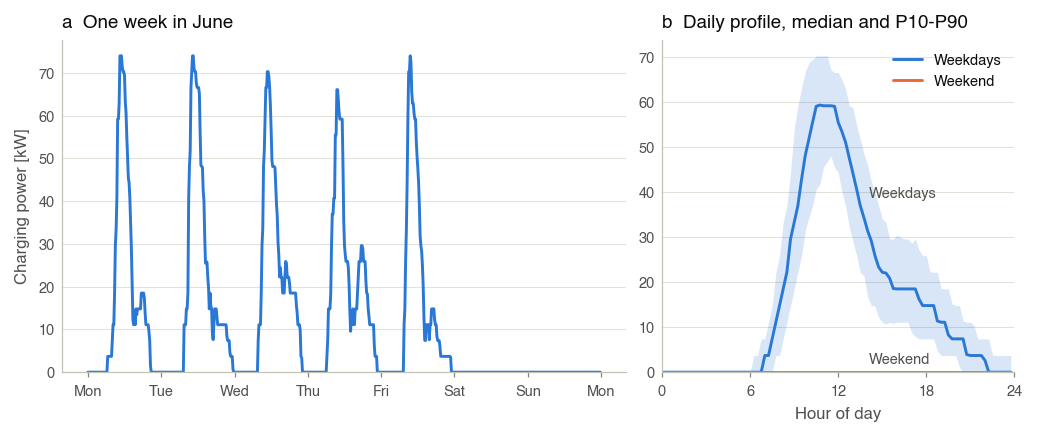

In [4]:
load = result.to_dataframe()["charging_total"]
week = load["2024-06-03":"2024-06-09"]

daily = load.groupby([load.index.dayofweek < 5, load.index.hour + load.index.minute / 60])
stats = daily.quantile([0.1, 0.5, 0.9]).unstack()

fig, (ax_week, ax_day) = plt.subplots(1, 2, width_ratios=[1.6, 1])

ax_week.plot(week.index, week.to_numpy(), color="C0")
ax_week.set_title("a  One week in June")
ax_week.set_ylabel("Charging power [kW]")
ax_week.xaxis.set_major_formatter(plt.matplotlib.dates.DateFormatter("%a"))
ax_week.set_ylim(0, None)

for (is_weekday, label), color in zip(
    [(True, "Weekdays"), (False, "Weekend")], ["C0", "C1"], strict=True
):
    band = stats.loc[is_weekday]
    ax_day.fill_between(band.index, band[0.1], band[0.9], color=color, alpha=0.18, linewidth=0)
    ax_day.plot(band.index, band[0.5], color=color, label=label)
    ax_day.annotate(
        label,
        (band.index[54], band[0.5].iloc[54]),
        xytext=(4, 4),
        textcoords="offset points",
        color="#52514e",
        fontsize=7,
    )
ax_day.set_title("b  Daily profile, median and P10-P90")
ax_day.set_xlabel("Hour of day")
ax_day.set_xticks(range(0, 25, 6))
ax_day.set_xlim(0, 24)
ax_day.set_ylim(0, None)
ax_day.legend(loc="upper right")

fig.savefig(FIGURES / "01_load_profile.pdf")

## Inputs are reproducible and shareable

In [5]:
output = Path("output")
scenario.to_yaml(output / "office.yaml")
result.realisation.save(output / "office_2024.json.gz")

reloaded = elvis.Realisation.load(output / "office_2024.json.gz")
np.array_equal(elvis.simulate(reloaded).load_profile_kw, result.load_profile_kw)

True